<a href="https://colab.research.google.com/github/anniechooimh/Hospitality-Analytics/blob/main/Capstone_Hospitality%20Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Upload the 5 data files from github.

In [2]:
import pandas as pd
import numpy as np

bookings = pd.read_csv("https://raw.githubusercontent.com/anniechooimh/Hospitality-Analytics/refs/heads/main/Bookings.csv")
customer_types = pd.read_csv("https://raw.githubusercontent.com/anniechooimh/Hospitality-Analytics/refs/heads/main/Customer%20Types.csv")
hotels = pd.read_csv("https://raw.githubusercontent.com/anniechooimh/Hospitality-Analytics/refs/heads/main/Hotels.csv")
market_segments = pd.read_csv("https://raw.githubusercontent.com/anniechooimh/Hospitality-Analytics/refs/heads/main/Market%20Segments.csv")
reservation_status = pd.read_csv("https://raw.githubusercontent.com/anniechooimh/Hospitality-Analytics/refs/heads/main/Reservation%20Status.csv")

### Review the dataset structure

In [3]:
display(bookings.head())
display(customer_types.head())
display(hotels.head())
display(market_segments.head())
display(reservation_status.head())


,Booking_ID,Hotel_ID,Market_Segment_ID,Customer_Type_ID,Reservation_ID,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,...,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,reservation_status_date
0,1,1,1,1,1,0,342,2015,July,27,...,0,0,3,NaN,NaN,0,0.0,0,0,2015-07-01
1,2,1,1,1,1,0,737,2015,July,27,...,0,0,4,NaN,NaN,0,0.0,0,0,2015-07-01
2,3,1,1,1,1,0,7,2015,July,27,...,0,0,0,NaN,NaN,0,75.0,0,0,2015-07-02
3,4,1,2,1,1,0,13,2015,July,27,...,0,0,0,304.0,NaN,0,75.0,0,0,2015-07-02
4,5,1,3,1,1,0,14,2015,July,27,...,0,0,0,240.0,NaN,0,98.0,0,1,2015-07-03


,Customer_Type_ID,customer_type,deposit_type,meal
0,1,Transient,No Deposit,BB
1,2,Transient,No Deposit,FB
2,3,Transient,No Deposit,HB
3,4,Contract,No Deposit,BB
4,5,Contract,No Deposit,HB


,Hotel_ID,hotel
0,1,Resort Hotel
1,2,City Hotel


,Market_Segment_ID,market_segment,distribution_channel
0,1,Direct,Direct
1,2,Corporate,Corporate
2,3,Online TA,TA/TO
3,4,Offline TA/TO,TA/TO
4,5,Complementary,Direct


,Reservation_ID,reservation_status
0,1,Check-Out
1,2,Canceled
2,3,No-Show


Observation: Bookings.csv is the main dataset with individual booking records. The other 4 files are lookup tables joined by ID columns.

In [4]:
#Identify total column and rows in the main dataset
bookings.shape

(119390, 28)

In [5]:
#Before cleaning
bookings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 28 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   Booking_ID                      119390 non-null  int64  
 1   Hotel_ID                        119390 non-null  int64  
 2   Market_Segment_ID               119390 non-null  int64  
 3   Customer_Type_ID                119390 non-null  int64  
 4   Reservation_ID                  119390 non-null  int64  
 5   is_canceled                     119390 non-null  int64  
 6   lead_time                       119390 non-null  int64  
 7   arrival_date_year               119390 non-null  int64  
 8   arrival_date_month              119390 non-null  object 
 9   arrival_date_week_number        119390 non-null  int64  
 10  arrival_date_day_of_month       119390 non-null  int64  
 11  stays_in_weekend_nights         119390 non-null  int64  
 12  stays_in_week_ni

In [6]:
print(bookings.describe())

          Booking_ID       Hotel_ID  Market_Segment_ID  Customer_Type_ID  \
count  119390.000000  119390.000000      119390.000000     119390.000000   
mean    59695.500000       1.664461           4.262032          5.089044   
std     34465.068657       0.472181           3.071532          5.250009   
min         1.000000       1.000000           1.000000          1.000000   
25%     29848.250000       1.000000           3.000000          1.000000   
50%     59695.500000       2.000000           3.000000          3.000000   
75%     89542.750000       2.000000           4.000000          8.000000   
max    119390.000000       2.000000          26.000000         36.000000   

       Reservation_ID    is_canceled      lead_time  arrival_date_year  \
count   119390.000000  119390.000000  119390.000000      119390.000000   
mean         1.380526       0.370416     104.011416        2016.156554   
std          0.505913       0.482918     106.863097           0.707476   
min          1.0000

### Data Cleansing and Preparation - Identify missing values, handle empty rows, correct data types to prepare the data for analysis.

In [7]:
#Identify columns with missing values on the booking dataset
print("\n**Missing values per column before cleaning:")
print(bookings.isnull().sum())


**Missing values per column before cleaning:
Booking_ID                             0
Hotel_ID                               0
Market_Segment_ID                      0
Customer_Type_ID                       0
Reservation_ID                         0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
country                              488
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
booking_changes                        0
agent                              16340
company                           112593
days_in_wai

Observation and treatment to missing:
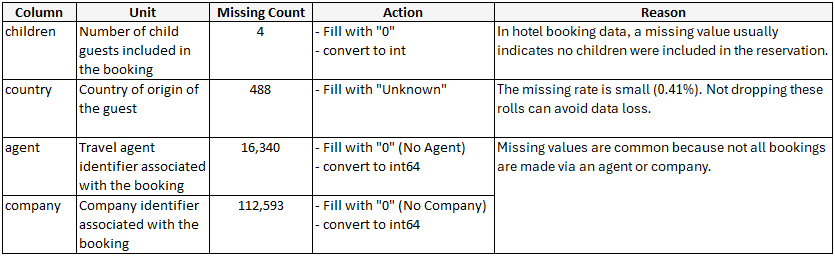

In [8]:
#Update the missing values
bookings['children'] = bookings['children'].fillna(0).astype(int)    # 0 = no children in booking

bookings['country'] = bookings['country'].fillna('Unknown')
bookings['agent'] = bookings['agent'].fillna(0).astype('Int64')      # 0 = no agent
bookings['company'] = bookings['company'].fillna(0).astype('Int64')  # 0 = no company

print("\n**Missing values after cleaning:")
print(bookings.isnull().sum())


**Missing values after cleaning:
Booking_ID                        0
Hotel_ID                          0
Market_Segment_ID                 0
Customer_Type_ID                  0
Reservation_ID                    0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
country                           0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
booking_changes                   0
agent                             0
company                           0
days_in_waiting_list              0
adr                               0
required_car_parking_spaces       0
total_of_special_requests     

In [9]:
#Standardize column data types
bookings['reservation_status_date'] = pd.to_datetime(bookings['reservation_status_date'])
bookings['is_canceled'] = bookings['is_canceled'].astype(bool)
bookings['is_repeated_guest'] = bookings['is_repeated_guest'].astype(bool)

#Normalise the three separate date fields into a proper dateime column to enable time-series analysis
bookings['arrival_date'] = pd.to_datetime(
    bookings['arrival_date_year'].astype(str) + '-' +
    bookings['arrival_date_month'].astype(str) + '-' +
    bookings['arrival_date_day_of_month'].astype(str),
    format='%Y-%B-%d',   # %B expects full month name (e.g., January, February)
    errors='coerce'
)

#Calculate Total Nights and Total Price per booking
bookings['total_nights'] = bookings['stays_in_weekend_nights'] + bookings['stays_in_week_nights']
bookings['total_price'] = bookings['adr'] * bookings['total_nights']
print("\n**Total Nights and Total Price per booking:")
display(bookings[['Booking_ID','adr','total_nights','total_price']].head())

print("\n**Cleaned Dataset Info:")
display(bookings.info())

print("\n**Cleaned Dataset Head:")
display(bookings.head())



**Total Nights and Total Price per booking:


,Booking_ID,adr,total_nights,total_price
0,1,0.0,0,0.0
1,2,0.0,0,0.0
2,3,75.0,1,75.0
3,4,75.0,1,75.0
4,5,98.0,2,196.0



**Cleaned Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 31 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   Booking_ID                      119390 non-null  int64         
 1   Hotel_ID                        119390 non-null  int64         
 2   Market_Segment_ID               119390 non-null  int64         
 3   Customer_Type_ID                119390 non-null  int64         
 4   Reservation_ID                  119390 non-null  int64         
 5   is_canceled                     119390 non-null  bool          
 6   lead_time                       119390 non-null  int64         
 7   arrival_date_year               119390 non-null  int64         
 8   arrival_date_month              119390 non-null  object        
 9   arrival_date_week_number        119390 non-null  int64         
 10  arrival_date_day_of_month      

None


**Cleaned Dataset Head:


,Booking_ID,Hotel_ID,Market_Segment_ID,Customer_Type_ID,Reservation_ID,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,...,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,reservation_status_date,arrival_date,total_nights,total_price
0,1,1,1,1,1,False,342,2015,July,27,...,0,0,0,0.0,0,0,2015-07-01,2015-07-01,0,0.0
1,2,1,1,1,1,False,737,2015,July,27,...,0,0,0,0.0,0,0,2015-07-01,2015-07-01,0,0.0
2,3,1,1,1,1,False,7,2015,July,27,...,0,0,0,75.0,0,0,2015-07-02,2015-07-01,1,75.0
3,4,1,2,1,1,False,13,2015,July,27,...,304,0,0,75.0,0,0,2015-07-02,2015-07-01,1,75.0
4,5,1,3,1,1,False,14,2015,July,27,...,240,0,0,98.0,0,1,2015-07-03,2015-07-01,2,196.0


## **Data Analysis**
### Objective 1: Identify the main factors influencing booking cancellations

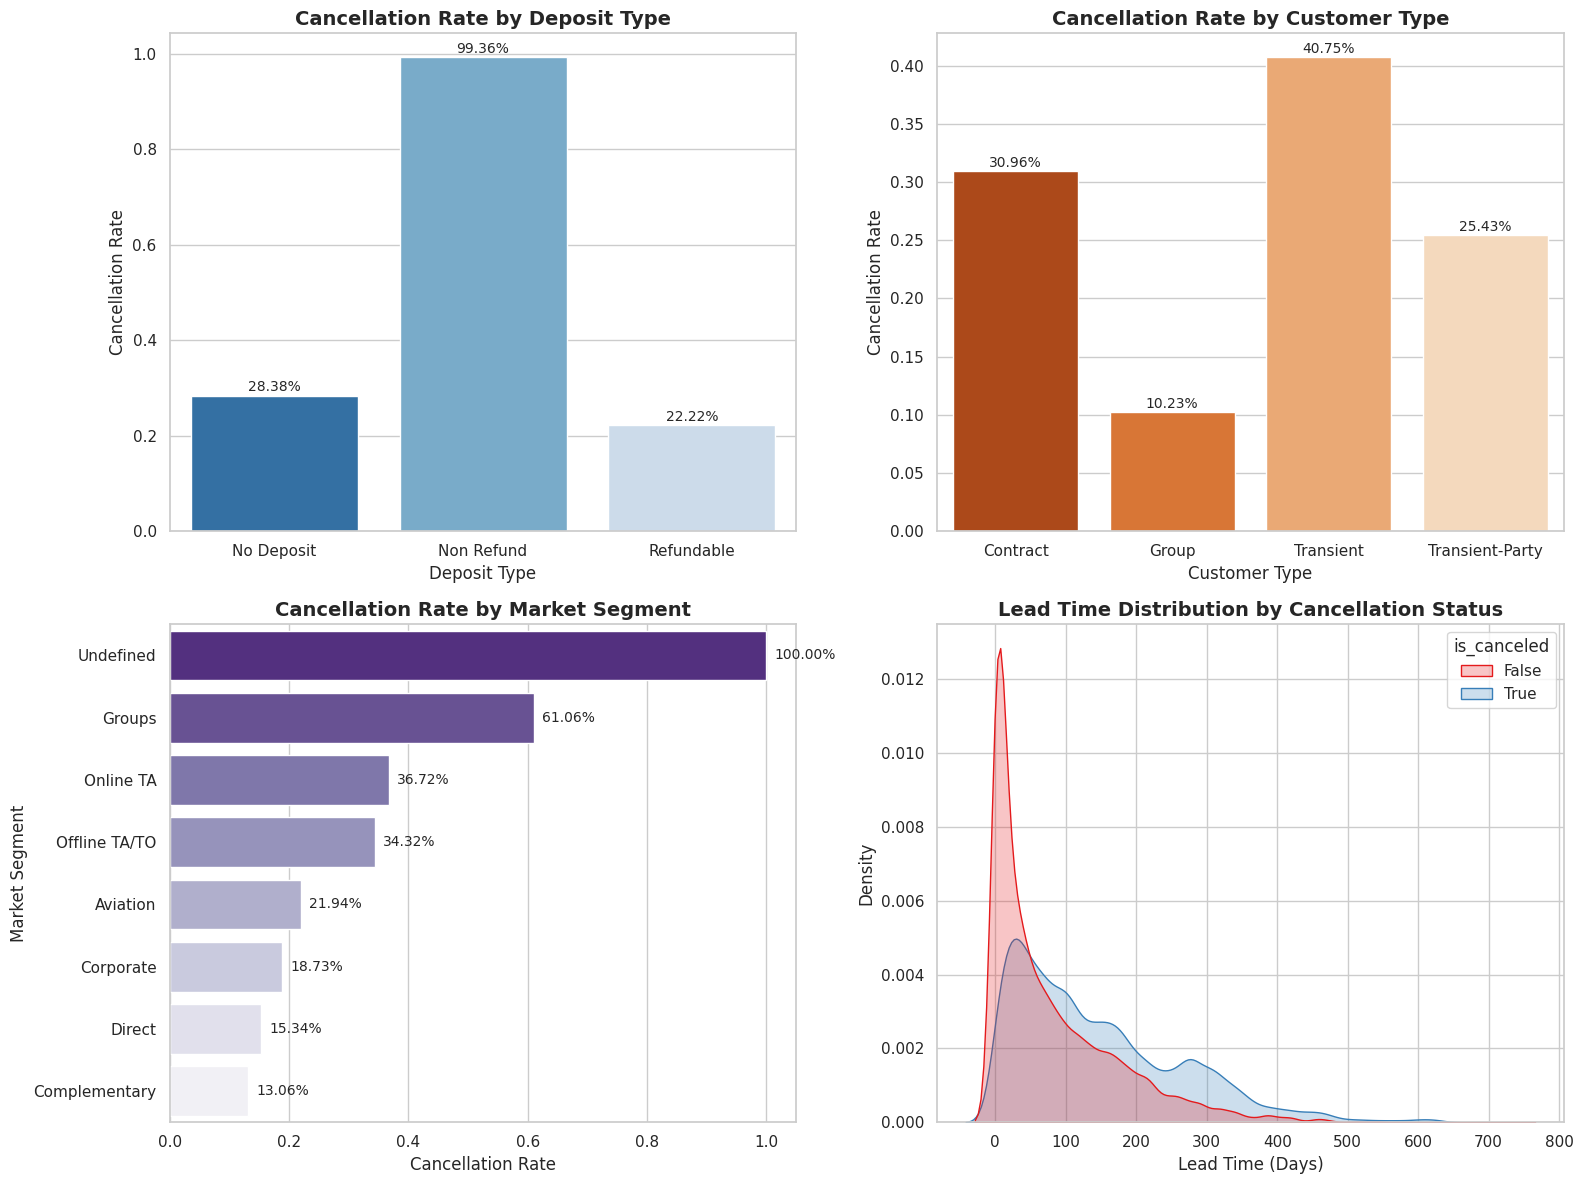

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Merge datasets to bring in descriptive categories
merged_booking = bookings.merge(customer_types, on='Customer_Type_ID', how='left')
merged_booking = merged_booking.merge(market_segments, on='Market_Segment_ID', how='left')
merged_booking = merged_booking.merge(hotels, on='Hotel_ID', how='left')

# Create the missing numeric cancellation column
merged_booking['is_canceled_numeric'] = merged_booking['is_canceled'].astype(int)

# Set plotting style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# --- Plot 1: Cancellation Rate by Deposit Type ---
deposit_cancel = merged_booking.groupby('deposit_type')['is_canceled_numeric'].mean().reset_index()
ax1 = sns.barplot(x='deposit_type', y='is_canceled_numeric', data=deposit_cancel, ax=axes[0, 0], palette='Blues_r', hue='deposit_type', legend=False,)
for p in ax1.patches:
    ax1.annotate(f'{p.get_height():.2%}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontsize=10)
axes[0, 0].set_title('Cancellation Rate by Deposit Type', fontsize=14, fontweight='bold')
axes[0, 0].set_ylabel('Cancellation Rate')
axes[0, 0].set_xlabel('Deposit Type')

# --- Plot 2: Cancellation Rate by Customer Type ---
customer_cancel = merged_booking.groupby('customer_type')['is_canceled_numeric'].mean().reset_index()
ax2 = sns.barplot(x='customer_type', y='is_canceled_numeric', data=customer_cancel, ax=axes[0, 1], palette='Oranges_r', hue='customer_type', legend=False)
for p in ax2.patches:
    ax2.annotate(f'{p.get_height():.2%}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontsize=10)
axes[0, 1].set_title('Cancellation Rate by Customer Type', fontsize=14, fontweight='bold')
axes[0, 1].set_ylabel('Cancellation Rate')
axes[0, 1].set_xlabel('Customer Type')

# --- Plot 3: Cancellation Rate by Market Segment ---
market_cancel = merged_booking.groupby('market_segment')['is_canceled_numeric'].mean().sort_values(ascending=False).reset_index()
ax3 = sns.barplot(x='is_canceled_numeric', y='market_segment', data=market_cancel, ax=axes[1, 0], palette='Purples_r', orient='h', hue='market_segment', legend=False)
for p in ax3.patches:
    ax3.annotate(f'{p.get_width():.2%}', (p.get_width(), p.get_y() + p.get_height() / 2.), ha='left', va='center', xytext=(6, 0), textcoords='offset points', fontsize=10)
axes[1, 0].set_title('Cancellation Rate by Market Segment', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Cancellation Rate')
axes[1, 0].set_ylabel('Market Segment')

# --- Plot 4: Lead Time Distribution for Cancelled vs Not Cancelled ---
sns.kdeplot(data=merged_booking, x='lead_time', hue='is_canceled', common_norm=False, fill=True, ax=axes[1, 1], palette='Set1')
axes[1, 1].set_title('Lead Time Distribution by Cancellation Status', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Lead Time (Days)')
axes[1, 1].set_ylabel('Density')

plt.tight_layout()
plt.show()

Observations:

1.	Deposit Type: Bookings with Non-Refundable deposits show a near 100% cancellation rate (frequently associated with pre-planned high-risk group packages or strict agency conditions), while No Deposit sits around 28% and Refundable bookings near 22%
2.	Customer Type: Transient guests are the most volatile segment with over a 40% cancellation rate, whereas Group bookings customers are highly reliable and have the lowest cancellation rate at just 10.23%, indicating that group commitments are rarely canceled once they are finalized.
3.	Market Segment: Groups lead the cancellation rates at over 60%, followed closely by Online TAs (~37%). Direct bookings are the most reliable, with cancellation rates of only ~15%.
4.	Lead Time: There is a very high, sharp peak for completed bookings (the red line/area) near 0 to 50 days. This indicate bookings made closer to the arrival date (short lead time) have much lower uncertainty. Bookings made far in advance (longer lead times) display a significantly flatter, longer tail, meaning the further out a guest books, the higher the likelihood of cancellation.


### Objective 2: Analyze Occupancy Patterns

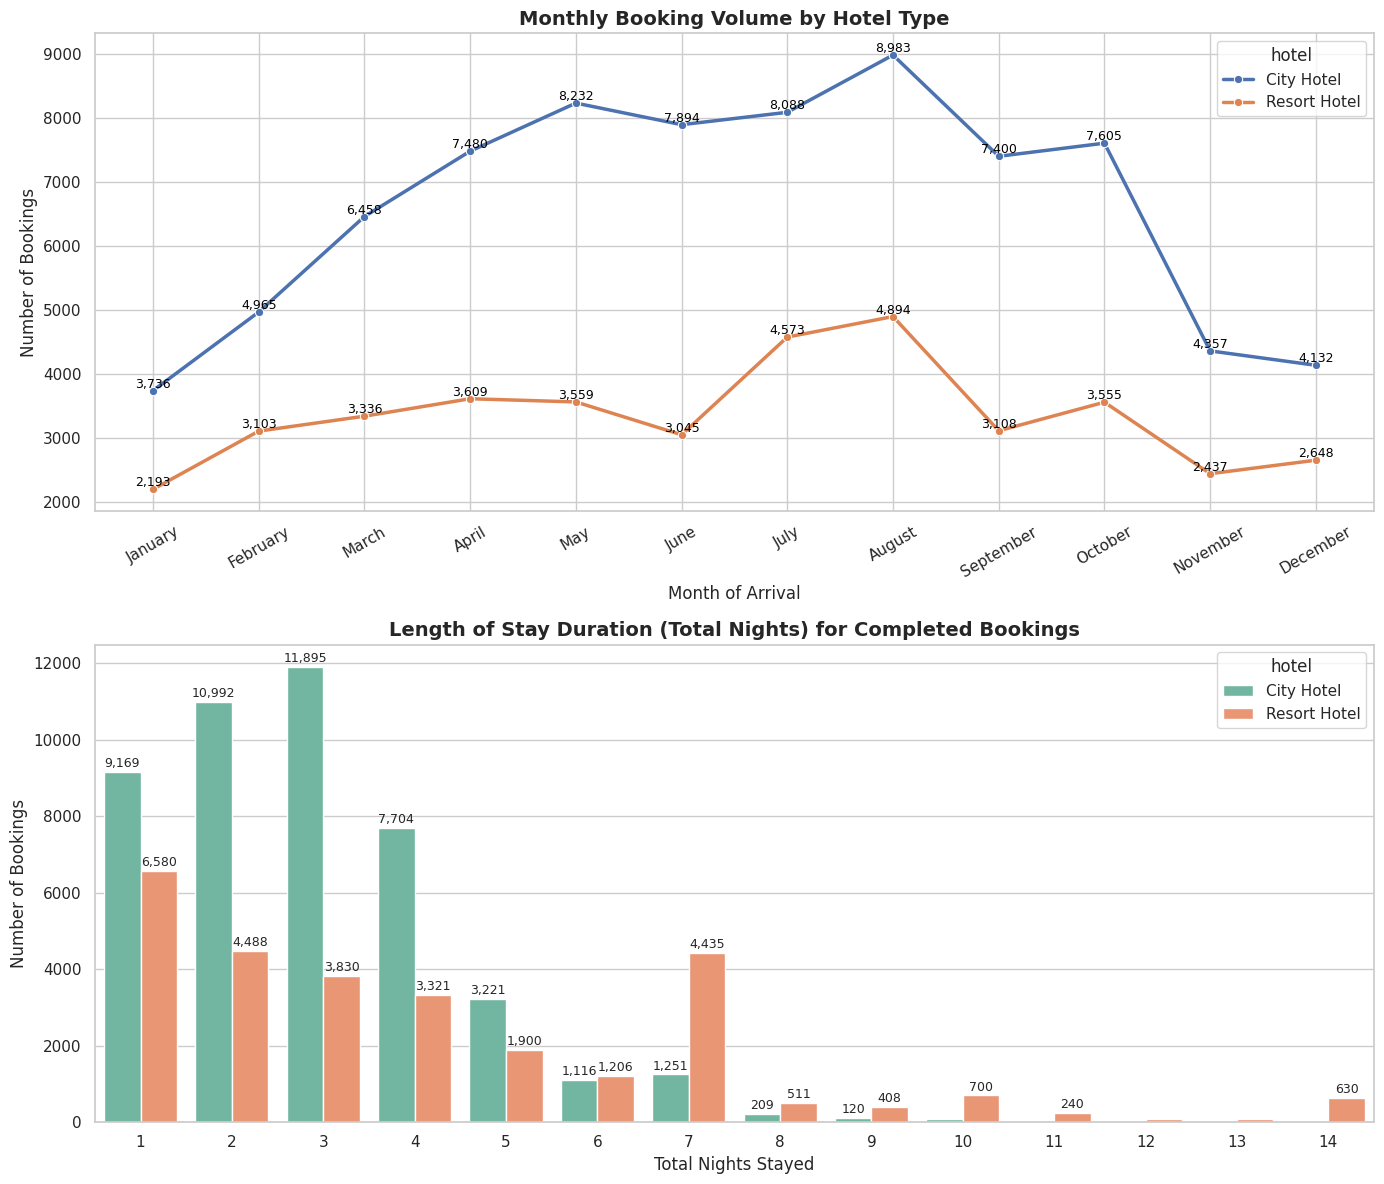

In [11]:
# Order months chronologically
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# 1. Monthly Seasonality Trend by Hotel Type
# Fixed: Replaced the undefined 'analysis_df' with the defined 'merged_booking'
monthly_bookings = merged_booking.groupby(['arrival_date_month', 'hotel']).size().reset_index(name='booking_count')
monthly_bookings['arrival_date_month'] = pd.Categorical(monthly_bookings['arrival_date_month'], categories=month_order, ordered=True)
monthly_bookings = monthly_bookings.sort_values('arrival_date_month')

ax1 = sns.lineplot(data=monthly_bookings, x='arrival_date_month', y='booking_count', hue='hotel', marker='o', linewidth=2.5, ax=axes[0])
for hotel_name in monthly_bookings['hotel'].unique():
    sub_data = monthly_bookings[monthly_bookings['hotel'] == hotel_name]
    for x, y in zip(sub_data['arrival_date_month'], sub_data['booking_count']):
        ax1.text(x, y, f'{y:,}', color='black', ha='center', va='bottom', fontsize=9)

axes[0].set_title('Monthly Booking Volume by Hotel Type', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Month of Arrival')
axes[0].set_ylabel('Number of Bookings')
axes[0].tick_params(axis='x', rotation=30)

# 2. Length of Stay Distribution (Total Nights) for Completed Bookings
completed_bookings = merged_booking[~merged_booking['is_canceled']]
stay_duration = completed_bookings.groupby(['total_nights', 'hotel']).size().reset_index(name='booking_count')

# Filter to standard stays (1 to 14 nights) for clean visualization
stay_duration = stay_duration[stay_duration['total_nights'].between(1, 14)]

ax2 = sns.barplot(data=stay_duration, x='total_nights', y='booking_count', hue='hotel', ax=axes[1], palette='Set2')
for p in ax2.patches:
    height = p.get_height()
    if height > 100: # Only annotate visible bars
        ax2.annotate(f'{int(height):,}', (p.get_x() + p.get_width() / 2., height), ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontsize=9)

axes[1].set_title('Length of Stay Duration (Total Nights) for Completed Bookings', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Total Nights Stayed')
axes[1].set_ylabel('Number of Bookings')

plt.tight_layout()
plt.show()

Observations:
1. Monthly booking volume:
- City Hotels consistently maintain a much higher volume of bookings than Resort Hotels year-round. Their demand peaks in May (8,232 bookings) and reaches an annual high in August (8,983 bookings). There is a sharp decline in bookings during the winter months (November to January).
- Resort Hotels bookings are much lower but steadier throughout most of the year, peaking dramatically in the summer months of July (4,573) and August (4,894). This reflects a strong reliance on leisure travelers booking summer family vacations.
2. Length of Stay (Total Nights) for Completed Bookings:
- City Hotels (Short, Concentrated Stays): Stays at City Hotels are highly concentrated in the short-term range. The most common durations are 1 night (9,169 stays), 2 nights (10,992 stays), and 3 nights (~11,895 stays). Completed stays beyond 5 nights drop off dramatically, which perfectly aligns with business travel and weekend city breaks.
- Resort Hotels (Longer, Relaxed Stays): Stays at Resort Hotels are more evenly spread out. While 1 to 3 nights are still highly popular, there is a prominent secondary spike at 7 nights (~4,435 stays). This reflects the traditional weekly holiday booking model typical of resort properties.

### Objective 3: Evaluate Customer Segments

**Customer Segment Performance Summary:


,customer_type,total_bookings,cancellation_rate,avg_adr,total_revenue
2,Transient,89613,0.407463,107.013621,34199103.91
3,Transient-Party,25124,0.254299,86.084253,6544635.58
0,Contract,4076,0.309617,87.549637,1839077.75
1,Group,577,0.102253,83.488579,140680.29


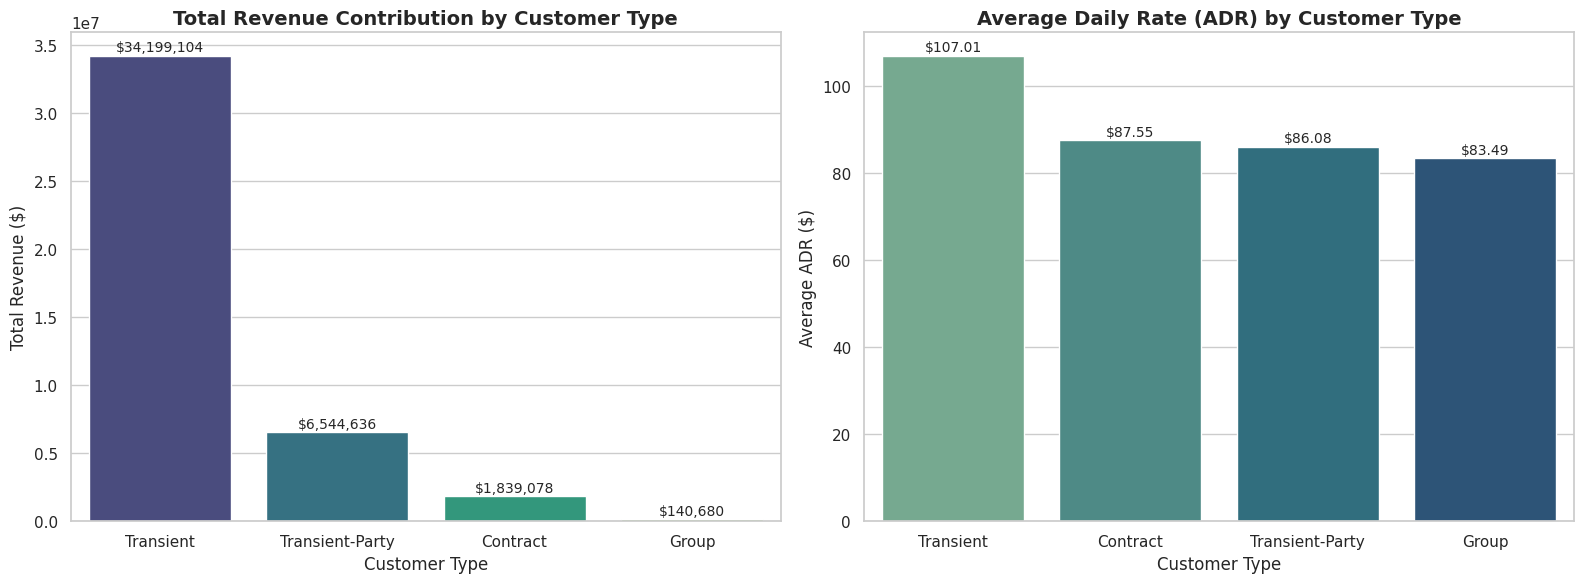

In [12]:
# Calculate metrics per Customer Type
customer_summary = merged_booking.groupby('customer_type').agg(
    total_bookings=('Booking_ID', 'count'),
    cancellation_rate=('is_canceled', 'mean'),
    avg_adr=('adr', 'mean'),
    total_revenue=('total_price', 'sum')
).reset_index()

# Sort by total revenue to identify the most valuable segment
customer_summary = customer_summary.sort_values(by='total_revenue', ascending=False)

print("**Customer Segment Performance Summary:")
display(customer_summary)

# Set plotting style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Revenue Contribution by Customer Type
ax1 = sns.barplot(x='customer_type', y='total_revenue', data=customer_summary, ax=axes[0], palette='viridis', hue='customer_type', legend=False)
for p in ax1.patches:
    ax1.annotate(f"${p.get_height():,.0f}", (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontsize=10)
axes[0].set_title('Total Revenue Contribution by Customer Type', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Total Revenue ($)')
axes[0].set_xlabel('Customer Type')

# Plot 2: Average Daily Rate (ADR) by Customer Type
ax2 = sns.barplot(x='customer_type', y='avg_adr', data=customer_summary.sort_values('avg_adr', ascending=False), ax=axes[1], palette='crest', hue='customer_type', legend=False)
for p in ax2.patches:
    ax2.annotate(f"${p.get_height():.2f}", (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontsize=10)
axes[1].set_title('Average Daily Rate (ADR) by Customer Type', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Average ADR ($)')
axes[1].set_xlabel('Customer Type')

plt.tight_layout()
plt.show()

Observations:

1. **Transient Customers (The Core Revenue Driver):**
- Revenue Contribution: Dominates the business, bringing in over $34.19 million, which accounts for the majority of total revenue.

- Pricing Power: Commands the highest Average Daily Rate (ADR) of $107.01, proving that individual walk-in or online direct bookings generate the highest yield per room night.

2. **Transient-Party Customers (The Volume Supporter):**
- Revenue Contribution: Represents the second-largest revenue segment at $6.54 million.

- Pricing Power: Yields a lower ADR of $86.08, suggesting that these customers (often traveling in groups or utilizing packaged transient rates) receive volume-based discounts.

3. **Contract Customers (The Steady Contributor):**
- Revenue Contribution: Generates a reliable $1.84 million in total revenue.

- Pricing Power: Commands a strong ADR of $87.55 (second highest overall), indicating good contract pricing agreements with corporate partners.

4. **Group Customers (The Niche Market):**
- Revenue Contribution: Yields the lowest revenue of $140,680 due to low booking volumes.

- Pricing Power: Carries the lowest ADR at $83.49, which is typical for group sales that undergo aggressive price negotiation.

### Objective 4: Assess Distribution Channel Performance

**Booking Channels Performance Summary:


,distribution_channel,total_bookings,cancellation_rate,avg_adr,total_revenue
3,TA/TO,97870,0.410259,103.292866,36096134.85
1,Direct,14645,0.174599,106.654983,5466100.80
0,Corporate,6677,0.220758,69.325204,1114093.46
2,GDS,193,0.191710,120.554301,45997.42
4,Undefined,5,0.800000,46.240000,1171.00


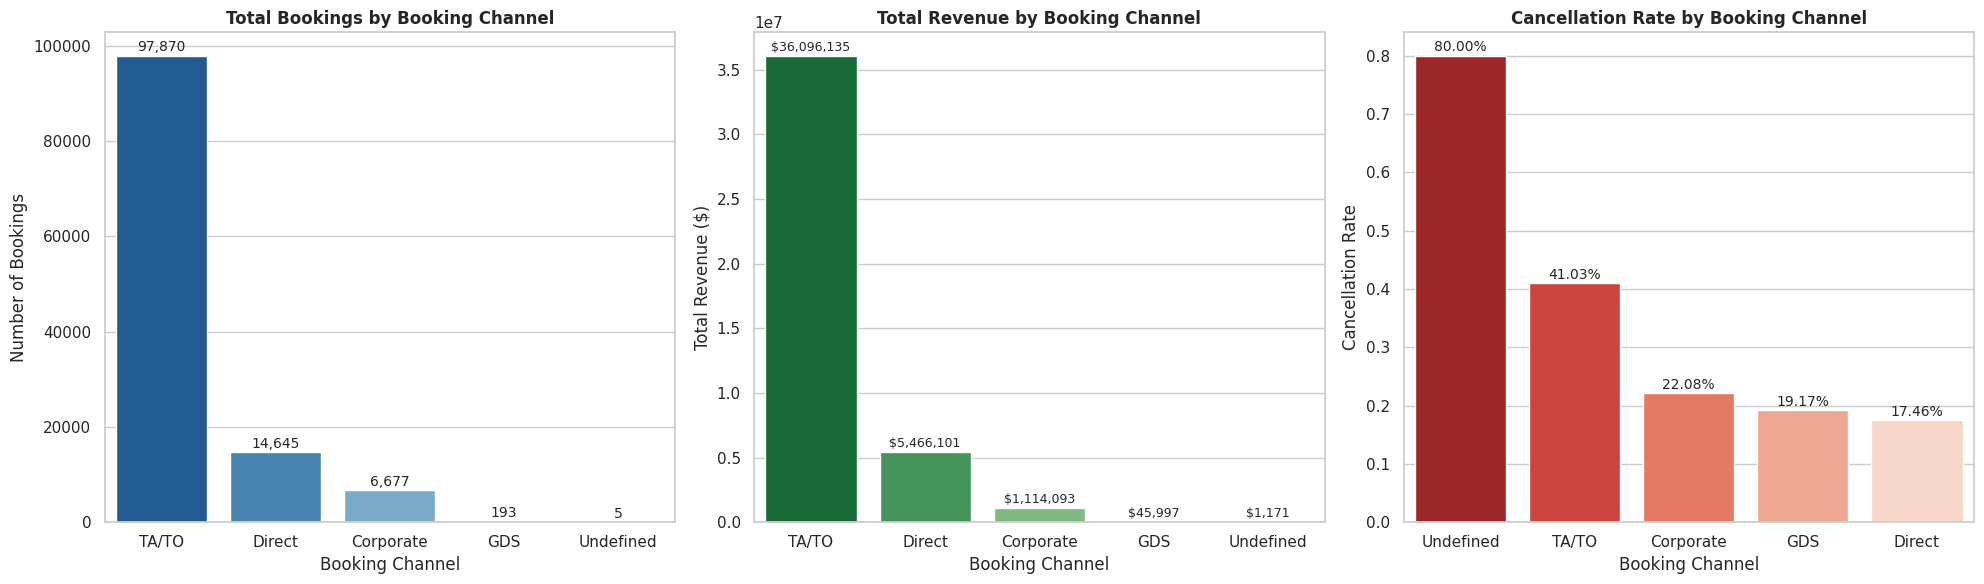

In [14]:
# Calculate metrics per Distribution Channel (Booking Channel)
channel_perf = merged_booking.groupby('distribution_channel').agg(
    total_bookings=('Booking_ID', 'count'),
    cancellation_rate=('is_canceled', 'mean'),
    avg_adr=('adr', 'mean'),
    total_revenue=('total_price', 'sum')
).reset_index()

# Sort by total revenue to identify the most lucrative channels
channel_perf = channel_perf.sort_values(by='total_revenue', ascending=False)

print("**Booking Channels Performance Summary:")
display(channel_perf)

# Set plotting style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Total Bookings by Channel
ax1 = sns.barplot(x='distribution_channel', y='total_bookings', data=channel_perf, ax=axes[0], palette='Blues_r', hue='distribution_channel', legend=False)
for p in ax1.patches:
    ax1.annotate(f"{p.get_height():,.0f}", (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontsize=10)
axes[0].set_title('Total Bookings by Booking Channel', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of Bookings')
axes[0].set_xlabel('Booking Channel')

# 2. Total Revenue by Channel
ax2 = sns.barplot(x='distribution_channel', y='total_revenue', data=channel_perf, ax=axes[1], palette='Greens_r', hue='distribution_channel', legend=False)
for p in ax2.patches:
    ax2.annotate(f"${p.get_height():,.0f}", (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontsize=9)
axes[1].set_title('Total Revenue by Booking Channel', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Total Revenue ($)')
axes[1].set_xlabel('Booking Channel')

# 3. Cancellation Rate by Channel
ax3 = sns.barplot(x='distribution_channel', y='cancellation_rate', data=channel_perf.sort_values('cancellation_rate', ascending=False), ax=axes[2], palette='Reds_r', hue='distribution_channel', legend=False)
for p in ax3.patches:
    ax3.annotate(f"{p.get_height():.2%}", (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontsize=10)
axes[2].set_title('Cancellation Rate by Booking Channel', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Cancellation Rate')
axes[2].set_xlabel('Booking Channel')

plt.tight_layout()
plt.show()

### Observations on Booking Channels (Distribution Channels):

1. TA/TO (Travel Agents / Tour Operators):
- Bookings & Revenue: This channel heavily dominates the business, driving 97,870 bookings and generating $36.10 million in total revenue.
- Risk Factor: However, it exhibits a very high cancellation rate of 41.03%. Relying too heavily on TA/TO places the hotel at significant risk of late cancellations and empty rooms.

2. Direct Bookings:
- Bookings & Revenue: Represents the second-largest channel with 14,645 bookings and $5.47 million in revenue.

- Reliability & ADR: This is the most healthy channel: it commands a high Average Daily Rate (ADR) of $106.65 and enjoys the lowest cancellation rate at just 17.46%.

3. Corporate Bookings:
- Bookings & Revenue: Generates 6,677 bookings yielding $1.11 million in revenue.

- Performance: While it has a much lower ADR ($69.33) due to corporate discounts, its cancellation rate is relatively low and stable at 22.08%.

4. GDS (Global Distribution System):
- Performance: Though GDS contributes only 193 bookings ($45,997 in revenue).

- It boasts the highest ADR of all channels at $120.55 with a relatively safe cancellation rate of 19.17%.



### Objective 5: Examine Reservation Outcomes

**Reservation Status Metrics Summary:


,reservation_status,total_bookings,avg_lead_time,avg_adr,avg_special_requests
0,Canceled,43017,147.308622,105.205241,0.323105
1,Check-Out,75166,79.984687,99.987693,0.714060
2,No-Show,1207,57.182270,96.378459,0.532726


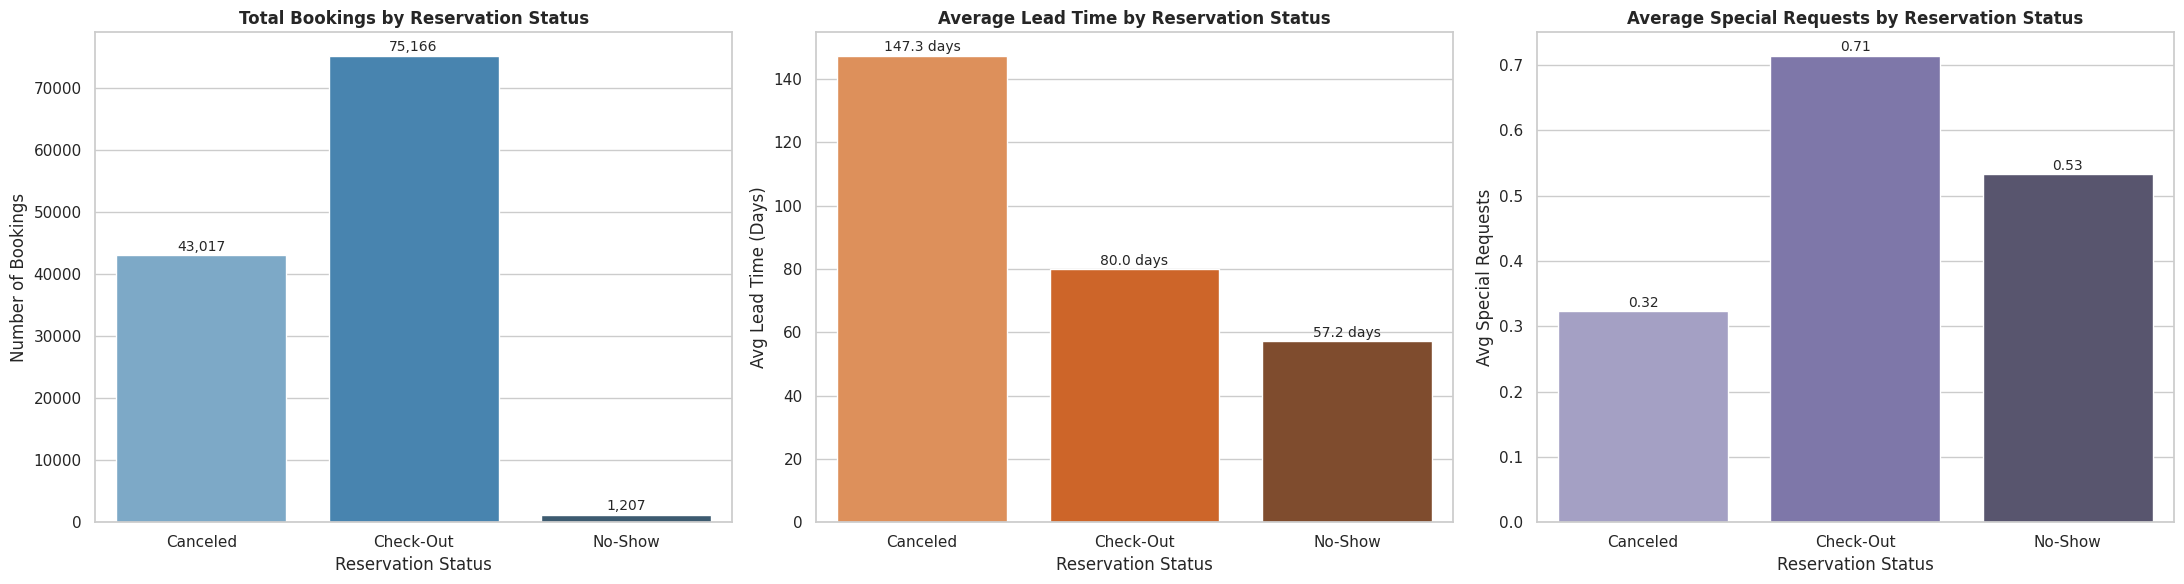

In [15]:
# 1. Merge with the reservation_status lookup table
merged_status = merged_booking.merge(reservation_status, on='Reservation_ID', how='left')

# 2. Compute aggregate metrics for each reservation status
status_analysis = merged_status.groupby('reservation_status').agg(
    total_bookings=('Booking_ID', 'count'),
    avg_lead_time=('lead_time', 'mean'),
    avg_adr=('adr', 'mean'),
    avg_special_requests=('total_of_special_requests', 'mean')
).reset_index()

print("**Reservation Status Metrics Summary:")
display(status_analysis)

# 3. Visualize relationships
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

# Plot 1: Total Bookings by Status
ax1 = sns.barplot(x='reservation_status', y='total_bookings', data=status_analysis, ax=axes[0], palette='Blues_d', hue='reservation_status', legend=False)
for p in ax1.patches:
    ax1.annotate(f"{p.get_height():,.0f}", (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontsize=10)
axes[0].set_title('Total Bookings by Reservation Status', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of Bookings')
axes[0].set_xlabel('Reservation Status')

# Plot 2: Average Lead Time by Status
ax2 = sns.barplot(x='reservation_status', y='avg_lead_time', data=status_analysis, ax=axes[1], palette='Oranges_d', hue='reservation_status', legend=False)
for p in ax2.patches:
    ax2.annotate(f"{p.get_height():.1f} days", (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontsize=10)
axes[1].set_title('Average Lead Time by Reservation Status', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Avg Lead Time (Days)')
axes[1].set_xlabel('Reservation Status')

# Plot 3: Average Special Requests by Status
ax3 = sns.barplot(x='reservation_status', y='avg_special_requests', data=status_analysis, ax=axes[2], palette='Purples_d', hue='reservation_status', legend=False)
for p in ax3.patches:
    ax3.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontsize=10)
axes[2].set_title('Average Special Requests by Reservation Status', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Avg Special Requests')
axes[2].set_xlabel('Reservation Status')

plt.tight_layout()
plt.show()

### Observations on Reservation Status Drivers:

1. **Lead Time Influence:**
   - Bookings that resulted in **Cancellations** had significantly higher average lead times compared to standard **Check-Outs**.
   - Managing booking windows and implementing overbooking buffers can mitigate risks from high lead time reservations.

2. **Special Requests Engagement:**
   - Completed bookings (**Check-Outs**) consistently show higher average special requests. Guests who engage by requesting modifications or special accommodations are highly likely to complete their stay.

3. **No-Show Insights:**
   - **No-Show** behavior correlates with low special request engagement, representing a distinct challenge requiring secure credit card holds or non-refundable deposit strategies.

### Visualize Booking Trends Over Time to Identify Seasonal Patterns

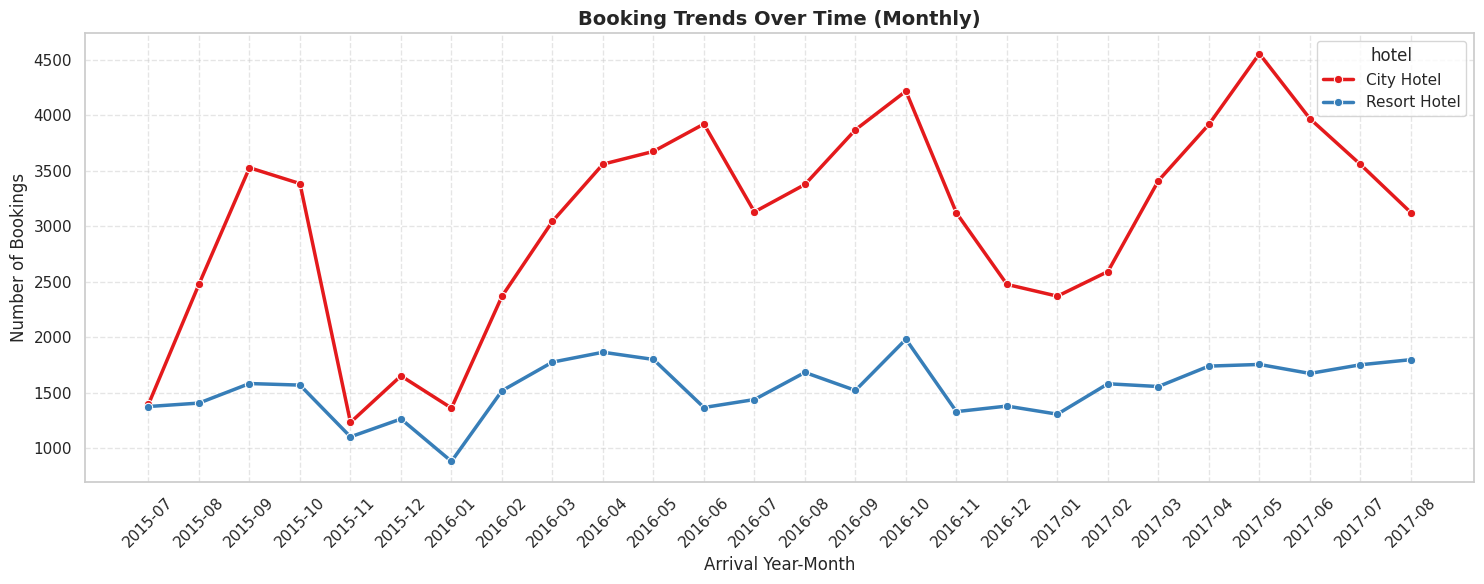

In [16]:
# Group bookings by Year and Month to view trends over time
merged_booking['arrival_year_month'] = merged_booking['arrival_date'].dt.to_period('M')
trend_df = merged_booking.groupby(['arrival_year_month', 'hotel']).size().reset_index(name='booking_count')
trend_df['arrival_year_month'] = trend_df['arrival_year_month'].astype(str)

# Create visualization
plt.figure(figsize=(15, 6))
sns.lineplot(data=trend_df, x='arrival_year_month', y='booking_count', hue='hotel', marker='o', linewidth=2.5, palette='Set1')

plt.title('Booking Trends Over Time (Monthly)', fontsize=14, fontweight='bold')
plt.xlabel('Arrival Year-Month', fontsize=12)
plt.ylabel('Number of Bookings', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Observation:
1. High Seasonality & Peak Demand:
- Both City Hotels and Resort Hotels experience their highest demand spike during the summer months (July and August) across consecutive years (2015, 2016, and 2017).
- City Hotels show secondary, smaller surges in spring (April/May) and autumn (September/October).
2. Winter Valley Trends:
- There is a highly consistent, dramatic drop in booking volume every November through January for both hotel types.
- Recommendation: Implement attractive winter packages, corporate retreat discounts, or seasonal marketing campaigns to offset low leisure demand during these colder months.
3. Year-Over-Year Growth:
- Looking at the peak in August 2015 vs August 2016, we can observe a healthy upward trajectory in maximum booking capacity, confirming positive market growth.


### Analyze the Relationship Between Length of Stay and Cancellation Status

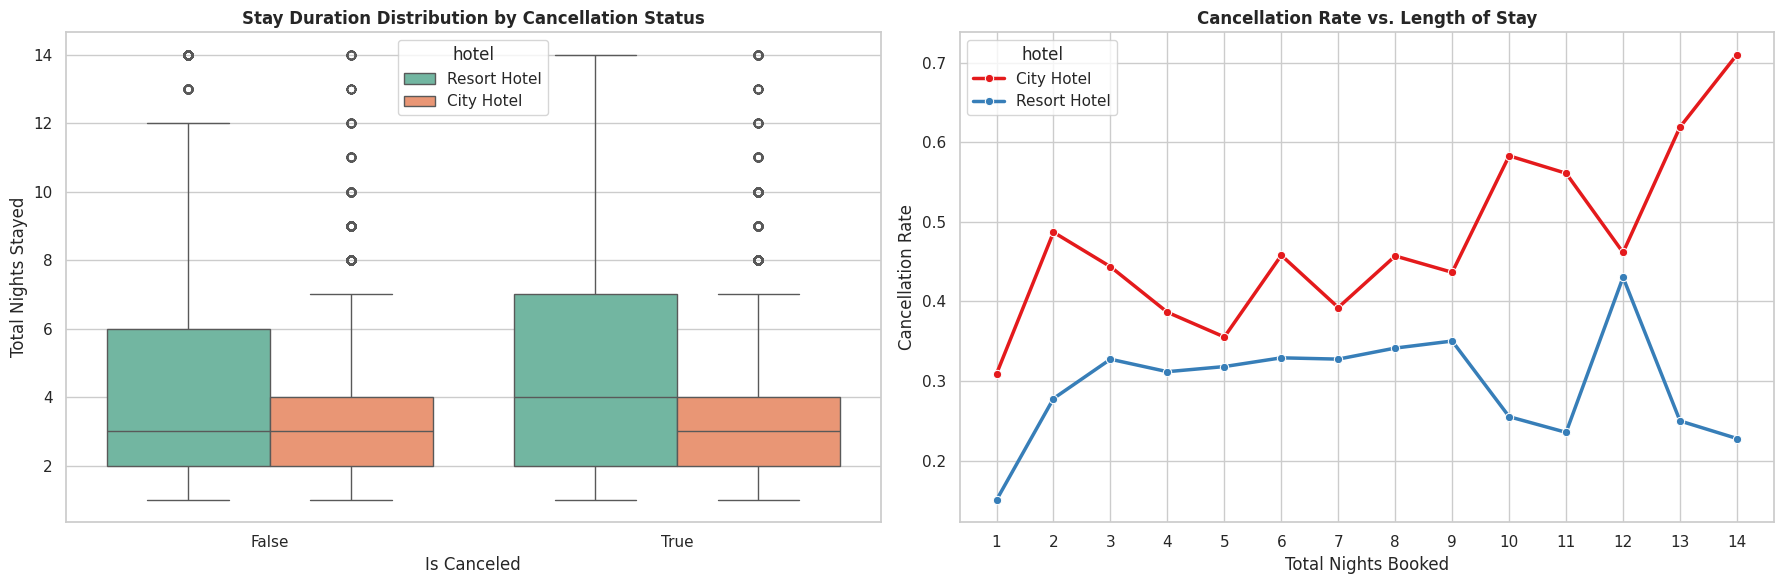

In [17]:
# Filter to standard stays (1 to 14 nights) for a cleaner visualization
stay_cancel_df = merged_booking[merged_booking['total_nights'].between(1, 14)].copy()

# Calculate cancellation rate per length of stay
stay_cancel_rate = stay_cancel_df.groupby(['total_nights', 'hotel'])['is_canceled_numeric'].mean().reset_index()

# Create subplots to show distribution of nights and cancellation rate
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Plot 1: Boxplot showing stay duration for cancelled vs. completed bookings
sns.boxplot(data=stay_cancel_df, x='is_canceled', y='total_nights', hue='hotel', ax=axes[0], palette='Set2')
axes[0].set_title('Stay Duration Distribution by Cancellation Status', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Is Canceled')
axes[0].set_ylabel('Total Nights Stayed')

# Plot 2: Lineplot showing cancellation rate as stay duration increases
sns.lineplot(data=stay_cancel_rate, x='total_nights', y='is_canceled_numeric', hue='hotel', marker='o', ax=axes[1], palette='Set1', linewidth=2.5)
axes[1].set_title('Cancellation Rate vs. Length of Stay', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Total Nights Booked')
axes[1].set_ylabel('Cancellation Rate')
axes[1].set_xticks(range(1, 15))

plt.tight_layout()
plt.show()

Observations:
1. Rising Risk with Longer Stays (City Hotels):
- For City Hotels, there is a strong upward correlation between length of stay and cancellation rate. While a 1-night stay has about a 31% cancellation rate, this climbs steadily, peaking at over 70% for 14-night stays.
- Recommendation: Implement stricter validation, larger deposit requirements, or non-refundable terms for extended stays in the city.

2. Stable but Volatile Trends (Resort Hotels):
- For Resort Hotels, cancellation rates hover relatively stable between 25% and 35% for standard holiday durations (1 to 9 nights).
- There is a noticeable drop in cancellations for exactly 10, 11, 13, and 14 nights (around 22-25%), suggesting that long-term vacationers who book these specific block durations have a highly firm travel intent.


### Predictive model: Determine whether an upcoming booking is likely to cancel

In [18]:
#Prepare the dataset for modeling by selecting features, encoding categorical variables, and splitting the data into training and test sets.

from sklearn.model_selection import train_test_split

# 1. Define predictor features
features_list = ['lead_time', 'adr', 'total_nights', 'booking_changes', 'total_of_special_requests', 'customer_type', 'market_segment', 'deposit_type']

# 2. Extract features (X) and binary target (y)
X = merged_booking[features_list].copy()
y = merged_booking['is_canceled'].astype(int)

# 3. Encode categorical features
X_encoded = pd.get_dummies(X, columns=['customer_type', 'market_segment', 'deposit_type'], drop_first=True)

# 4. Split into training and testing sets (80-20 split)
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42, stratify=y)

# 5. Verify shapes
print("Training features shape:", X_train.shape)
print("Test features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Test target shape:", y_test.shape)
print("\nFirst 3 rows of training features:")
display(X_train.head(3))

Training features shape: (95512, 17)
Test features shape: (23878, 17)
Training target shape: (95512,)
Test target shape: (23878,)

First 3 rows of training features:


,lead_time,adr,total_nights,booking_changes,total_of_special_requests,customer_type_Group,customer_type_Transient,customer_type_Transient-Party,market_segment_Complementary,market_segment_Corporate,market_segment_Direct,market_segment_Groups,market_segment_Offline TA/TO,market_segment_Online TA,market_segment_Undefined,deposit_type_Non Refund,deposit_type_Refundable
105447,20,98.0,2,0,0,False,True,False,False,False,False,False,False,True,False,False,False
85242,8,100.0,3,0,0,False,False,True,False,False,False,True,False,False,False,False,False
65604,93,95.0,3,0,0,False,True,False,False,False,False,False,True,False,False,True,False


In [19]:
#Train and tune a Random Forest classifier model to predict whether a hotel booking will be canceled.

from sklearn.ensemble import RandomForestClassifier

# 1. Instantiate the RandomForestClassifier with specified hyperparameters
rf_model = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)

# 2. Fit the model on the training set
print("Training the Random Forest model...")
rf_model.fit(X_train, y_train)

# 3. Generate class predictions and probabilities on the test set
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

print("Model training complete!")
print("Predictions shape:", y_pred.shape)
print("Probabilities shape:", y_prob.shape)

Training the Random Forest model...
Model training complete!
Predictions shape: (23878,)
Probabilities shape: (23878,)


**Model Performance Metrics:
Accuracy:  0.8241
Precision: 0.8481
Recall:    0.6399
F1-Score:  0.7294
AUC-ROC:   0.8881


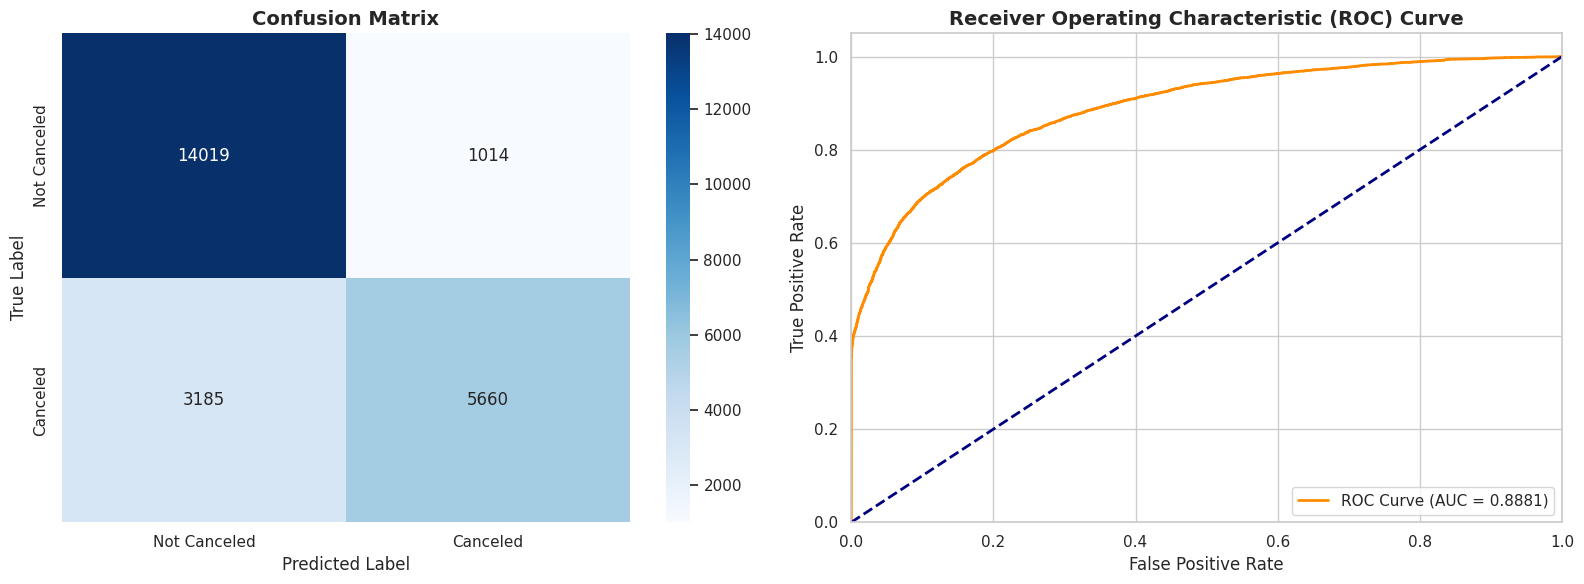

In [20]:
#Evaluate model performance using metrics such as Accuracy, Precision, Recall, F1-Score, and AUC-ROC, and to visualize the performance using a confusion matrix and ROC curve.

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate classification metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc_roc = roc_auc_score(y_test, y_prob)

print(f"**Model Performance Metrics:")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"AUC-ROC:   {auc_roc:.4f}")

# 2. Plot Confusion Matrix and ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Not Canceled', 'Canceled'],
            yticklabels=['Not Canceled', 'Canceled'])
axes[0].set_title('Confusion Matrix', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {auc_roc:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Receiver Operating Characteristic (ROC) Curve', fontsize=14, fontweight='bold')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

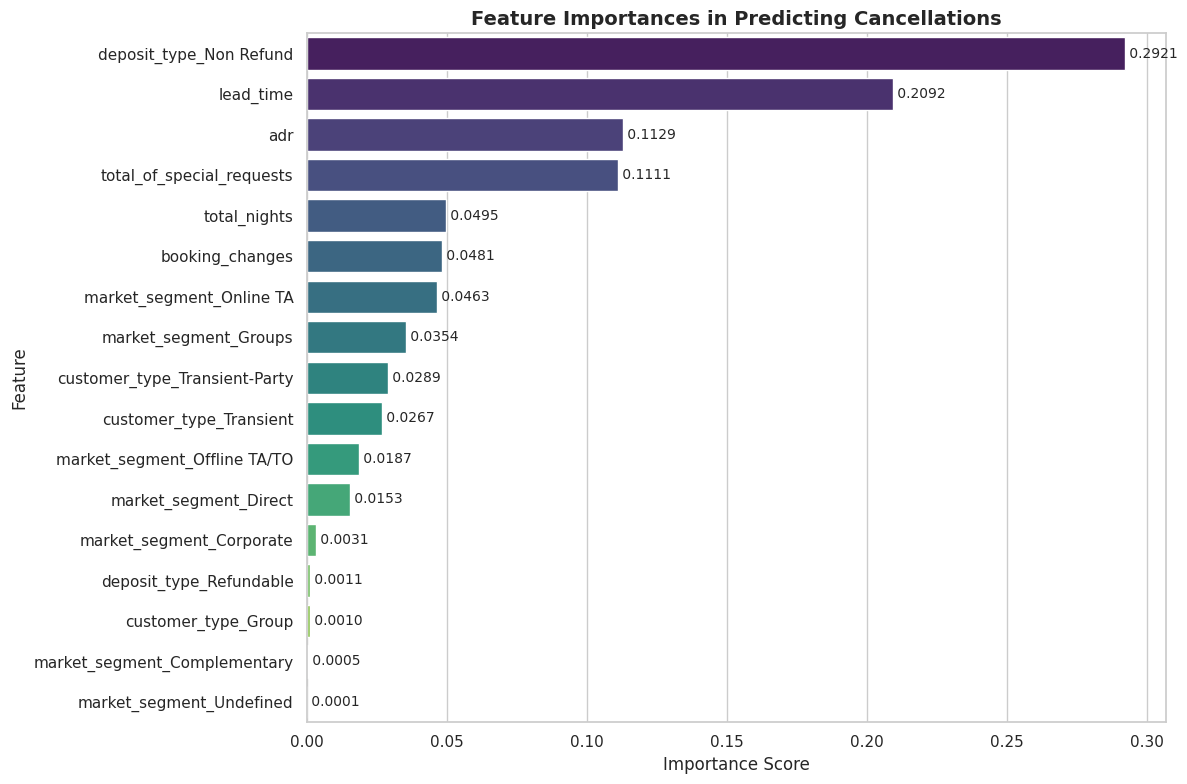

In [21]:
#Analyze and plot feature importances to identify key drivers

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Get feature importances from the trained RF model
importances = rf_model.feature_importances_
feature_names = X_train.columns

# 2. Create a DataFrame for easy sorting and plotting
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# 3. Plot Feature Importances
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis', hue='Feature', legend=False)

# Annotate the values on the bars
for index, value in enumerate(feature_importance_df['Importance']):
    plt.text(value, index, f' {value:.4f}', va='center', fontsize=10)

plt.title('Feature Importances in Predicting Cancellations', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

### Top Predictors of Cancellations:

1.	Deposit Type (Non-Refundable) (deposit_type_Non Refund ~ 0.2921):
- This is the single most influential feature in our model. Bookings designated as non-refundable are highly correlated with cancellation outcomes, likely due to specific reservation structures, group packages, or agent behaviors.
2.	Lead Time (lead_time ~ 0.2092):
- The amount of time elapsed between booking and the scheduled arrival date is the second most critical factor. Longer lead times introduce more uncertainty and higher probabilities of plan changes, whereas short-term bookings are highly stable.
3.	Average Daily Rate (adr ~ 0.1129):
- Pricing power strongly influences cancellation behavior. Higher room rates create a stronger incentive for guests to cancel or seek cheaper alternatives if their plans become flexible.
4.	Total Special Requests (total_of_special_requests ~ 0.1111):
- Guest engagement acts as a major indicator of intent. Customers who submit special requests are significantly more likely to complete their stay, whereas those with zero requests represent higher cancellation and no-show risks.
5.	Length of Stay (total_nights ~ 0.0495) and Booking Changes (booking_changes ~ 0.0481):
- Longer stays carry a slightly higher risk of cancellation (especially in City Hotels). Frequent modifications to a reservation prior to arrival indicate volatility, yet can sometimes stabilize the reservation compared to a completely un-interacted booking.


In [23]:
# export df into CSV file
bookings.to_csv('bookings_clean.csv', index=False)

from google.colab import files
files.download('bookings_clean.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>